# SHAP / Explainable AI for Final Dementia Classifier

This notebook is a **standalone explainability notebook** for the final saved multiclass dementia classifier bundle.

It does four things:

1. Loads the saved model bundle (`dementia_classifier_bundle.joblib`)
2. Rebuilds the exact train/test feature matrices from the cohort file
3. Computes **SHAP explanations** for the final logistic regression model
4. Exports:
   - global SHAP plots
   - per-class feature importance tables
   - local explanation plots
   - vascular threshold margin table

The notebook is written to match the training pipeline used in `02_train_baseline_model_full_final.ipynb`.


## 0) Configuration

Update the paths below only if your notebook location differs from your project structure.

Expected project layout:
- `../output/cohort_E8b_vascular_signal_H5.csv`
- `../output/dementia_classifier_bundle.joblib`


In [1]:

import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# User config
# ------------------------------------------------------------------
EXP_NAME = "E8b_vascular_signal"
H = 5
RANDOM_STATE = 42

# Change these if needed
OUTPUT_DIR = Path("..") / "output"
BUNDLE_PATH = OUTPUT_DIR / "dementia_classifier_bundle.joblib"
COHORT_PATH = OUTPUT_DIR / f"cohort_{EXP_NAME}_H{H}.csv"

SHAP_OUT_DIR = OUTPUT_DIR / "shap_outputs"
FIG_DIR = SHAP_OUT_DIR / "figures"
TABLE_DIR = SHAP_OUT_DIR / "tables"

SHAP_OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Bundle path:", BUNDLE_PATH)
print("Cohort path:", COHORT_PATH)
print("Output dir :", SHAP_OUT_DIR)

if not BUNDLE_PATH.exists():
    raise FileNotFoundError(f"Could not find saved model bundle: {BUNDLE_PATH}")

if not COHORT_PATH.exists():
    raise FileNotFoundError(f"Could not find cohort file: {COHORT_PATH}")


c:\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Bundle path: ..\output\dementia_classifier_bundle.joblib
Cohort path: ..\output\cohort_E8b_vascular_signal_H5.csv
Output dir : ..\output\shap_outputs


## 1) Load saved model bundle

In [2]:

bundle = joblib.load(BUNDLE_PATH)

clf_best = bundle["model"]
best_T = bundle["threshold"]
class_order = np.array(bundle["class_order"])
feature_cols = list(bundle["feature_cols"])

print("Loaded classes:", class_order.tolist())
print("Vascular threshold:", best_T)
print("Number of original feature columns:", len(feature_cols))

preprocess = clf_best.named_steps["preprocess"]
lr_model = clf_best.named_steps["model"]

print("\nPipeline steps:", clf_best.named_steps.keys())
print("Underlying model:", type(lr_model).__name__)


Loaded classes: ['AD', 'NoDementia_Hy', 'PD_LBD', 'Vascular']
Vascular threshold: 0.36
Number of original feature columns: 67

Pipeline steps: dict_keys(['preprocess', 'model'])
Underlying model: LogisticRegression


## 2) Rebuild the exact train/test split used by the training notebook

In [3]:

df = pd.read_csv(COHORT_PATH)
print("Loaded cohort:", df.shape)
display(df.head(3))
print(df["label"].value_counts(dropna=False))


Loaded cohort: (38341, 74)


,NACCID,baseline_date,label,max_follow_years,has_H_followup,has_dementia_H,NACCAGE,SEX,RACE,HISPANIC,...,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,STROKE_TIA_ANY,VASC_MED_COUNT,GAIT_ANY,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,Censored,3.296372,False,False,62.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0,0.0,0,NaN,NaN,NaN
1,NACC000034,2015-07-16,NoDementia_Hy,6.986995,True,False,79.0,2.0,1.0,0.0,...,NaN,NaN,NaN,NaN,0,2.0,0,1.0,1.0,0.0
2,NACC000067,2012-05-23,Censored,2.088980,False,False,60.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0,1.0,1,1.0,0.0,NaN


label
Censored         23300
NoDementia_Hy    11083
AD                3013
MixedOrOther       504
PD_LBD             289
Vascular           152
Name: count, dtype: int64


In [4]:

def fix_categorical_codes(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    CAT_CODE_VARS = [c for c in ["SEX", "RACE", "HISPANIC", "NACCUDSD"] if c in X.columns]
    STD_MISS = {-4, 9}

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        s = s.mask(s.isin(list(STD_MISS)), np.nan)
        X[c] = s

    if "RACE" in X.columns:
        X["RACE"] = X["RACE"].mask(X["RACE"].isin([99]), np.nan)

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        X[c] = s.map(lambda v: np.nan if pd.isna(v) else str(int(v))).astype(object)

    if "EDUC" in X.columns:
        educ_num = pd.to_numeric(X["EDUC"], errors="coerce")
        _ = educ_num  # kept for parity with training notebook

    X = X.replace({pd.NA: np.nan})
    for c in X.columns:
        if X[c].dtype == "bool":
            X[c] = X[c].astype(int)

    return X


def prepare_experiment_df(df_in: pd.DataFrame, exp_name: str):
    df_in = df_in.copy()

    KEEP = {"AD", "NoDementia_Hy", "PD_LBD", "Vascular"}
    df4 = df_in[df_in["label"].isin(KEEP)].copy()

    drop_cols = [
        c for c in [
            "NACCID", "baseline_date", "label", "has_H_followup",
            "has_dementia_H", "max_follow_years", "abs_days_from_baseline",
            "NACCUDSD"
        ]
        if c in df4.columns
    ]

    # Training notebook logic retained exactly
    if exp_name == "E8_clean_vascular":
        raw_vasc = [
            "DIABETES","HYPERTEN","HYPERCHO","CVAFIB","CBSTROKE",
            "CBTIA","CVCHF","CVANGINA","CVBYPASS","CVHVALVE"
        ]
        drop_cols += [c for c in raw_vasc if c in df4.columns]

        raw_meds = [
            "NACCLIPL","NACCAC","NACCBETA","NACCCCBS",
            "NACCDIUR","NACCANGI","NACCVASD"
        ]
        drop_cols += [c for c in raw_meds if c in df4.columns]

    if exp_name == "E9_clean_exec_ratio":
        drop_cols += [c for c in ["TRAILA","TRAILB","TRAILA_missing","TRAILB_missing"] if c in df4.columns]

    X = df4.drop(columns=[c for c in drop_cols if c in df4.columns]).copy()
    y = df4["label"].astype(str).copy()

    return df4, X, y


df4, X, y = prepare_experiment_df(df, EXP_NAME)
X = fix_categorical_codes(X)

# Reorder to the exact saved feature order
missing_in_current = [c for c in feature_cols if c not in X.columns]
extra_in_current = [c for c in X.columns if c not in feature_cols]

if missing_in_current:
    raise ValueError(f"These saved feature columns are missing from current cohort file: {missing_in_current[:20]}")

if extra_in_current:
    print("Warning: extra columns exist in the rebuilt cohort and will be dropped.")
    print(extra_in_current[:20])

X = X[feature_cols].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("df4 shape   :", df4.shape)
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("\nTrain label counts:")
print(y_train.value_counts())
print("\nTest label counts:")
print(y_test.value_counts())


df4 shape   : (14537, 74)
X_train shape: (11629, 67)
X_test shape : (2908, 67)

Train label counts:
label
NoDementia_Hy    8866
AD               2410
PD_LBD            231
Vascular          122
Name: count, dtype: int64

Test label counts:
label
NoDementia_Hy    2217
AD                603
PD_LBD             58
Vascular           30
Name: count, dtype: int64


## 3) Transform data using the saved preprocessing pipeline

In [5]:

X_train_pre = preprocess.transform(X_train)
X_test_pre = preprocess.transform(X_test)

feature_names_pre = preprocess.get_feature_names_out()

print("Transformed train shape:", X_train_pre.shape)
print("Transformed test shape :", X_test_pre.shape)
print("Number of transformed features:", len(feature_names_pre))

feature_names_pre[:20]


Transformed train shape: (11629, 74)
Transformed test shape : (2908, 74)
Number of transformed features: 74


array(['num__NACCAGE', 'num__EDUC', 'num__NACCMMSE', 'num__NACCMOCA',
       'num__TRAILA', 'num__TRAILB', 'num__ANIMALS', 'num__BOSTON',
       'num__CDRSUM', 'num__CDRGLOB', 'num__NACCMMSE_missing',
       'num__NACCMOCA_missing', 'num__TRAILA_missing',
       'num__TRAILB_missing', 'num__CDRSUM_missing', 'num__COGFLUC',
       'num__BEVHALL', 'num__BEREM', 'num__PARKSIGN', 'num__BRADY'],
      dtype=object)

## 4) Helper functions

In [6]:

def predict_with_vascular_threshold(proba: np.ndarray, class_order, best_T: float):
    class_order = np.array(class_order)
    vas_idx = list(class_order).index("Vascular")
    preds = []
    for p in proba:
        if p[vas_idx] >= best_T:
            preds.append("Vascular")
        else:
            preds.append(class_order[np.argmax(p)])
    return np.array(preds)


def collapse_feature_name(name: str) -> str:
    if name.startswith("num__"):
        return name.replace("num__", "")
    if name.startswith("cat__"):
        name = name.replace("cat__", "")
        # OneHotEncoder names typically look like VAR_level.
        # Split from the right so names with underscores stay mostly intact.
        if "_" in name:
            return name.rsplit("_", 1)[0]
        return name
    return name


def row_to_dense(row):
    if hasattr(row, "toarray"):
        return row.toarray().ravel()
    return np.asarray(row).ravel()


def save_current_fig(filename: str):
    out = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


## 5) Build SHAP explainer

In [7]:

rng = np.random.default_rng(42)
bg_size = min(300, X_train_pre.shape[0])
bg_idx = rng.choice(X_train_pre.shape[0], size=bg_size, replace=False)
X_background = X_train_pre[bg_idx]

sample_size = min(300, X_test_pre.shape[0])
X_explain = X_test_pre[:sample_size]

explainer = shap.LinearExplainer(
    lr_model,
    X_background,
    feature_names=feature_names_pre
)

shap_exp = explainer(X_explain)

print("Type:", type(shap_exp))
print("SHAP values shape:", np.shape(shap_exp.values))
print("Base values shape:", np.shape(shap_exp.base_values))
print("Explain subset size:", sample_size)


Type: <class 'shap._explanation.Explanation'>
SHAP values shape: (300, 74, 4)
Base values shape: (300, 4)
Explain subset size: 300


## 6) Global SHAP summary plots for each class


===== Global SHAP summary: AD =====


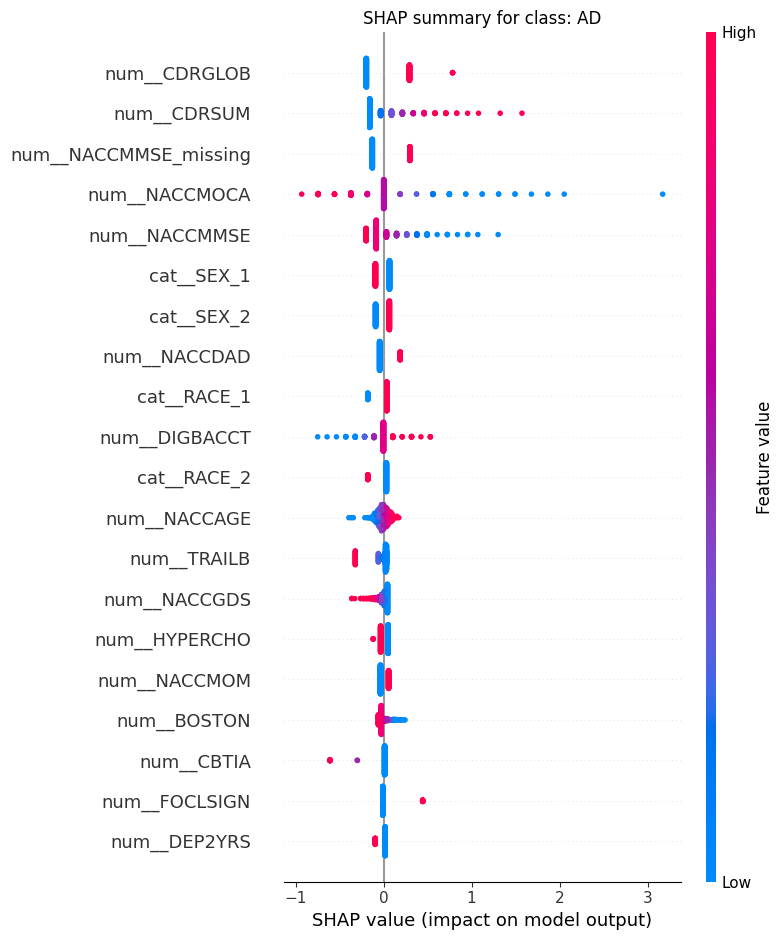

Saved: ..\output\shap_outputs\figures\summary_AD.png

===== Global SHAP summary: NoDementia_Hy =====


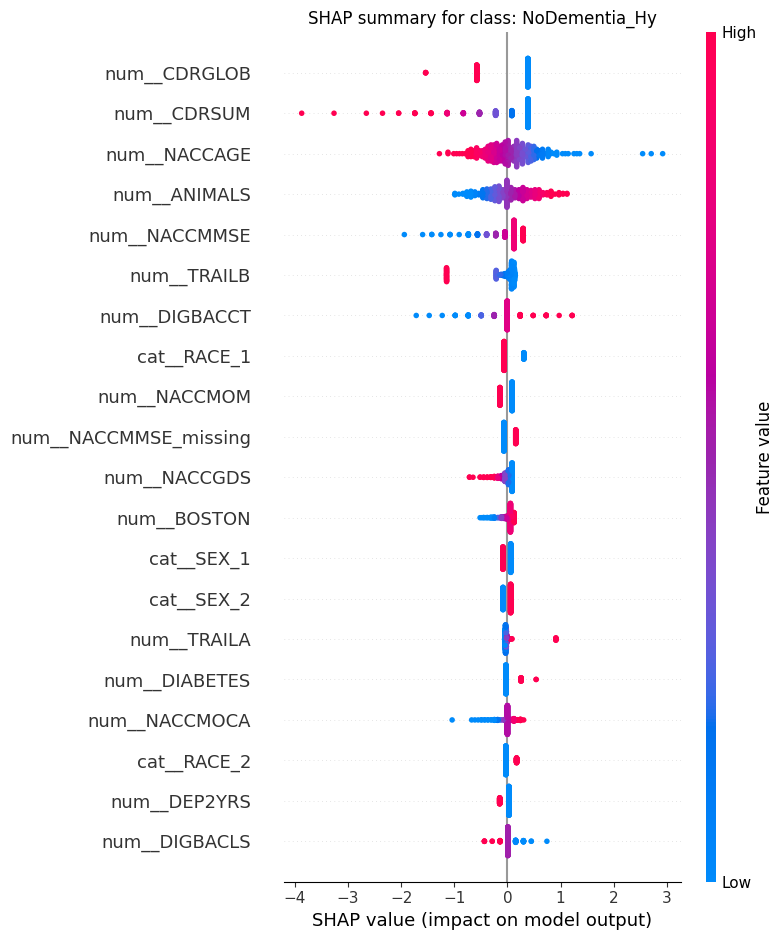

Saved: ..\output\shap_outputs\figures\summary_NoDementia_Hy.png

===== Global SHAP summary: PD_LBD =====


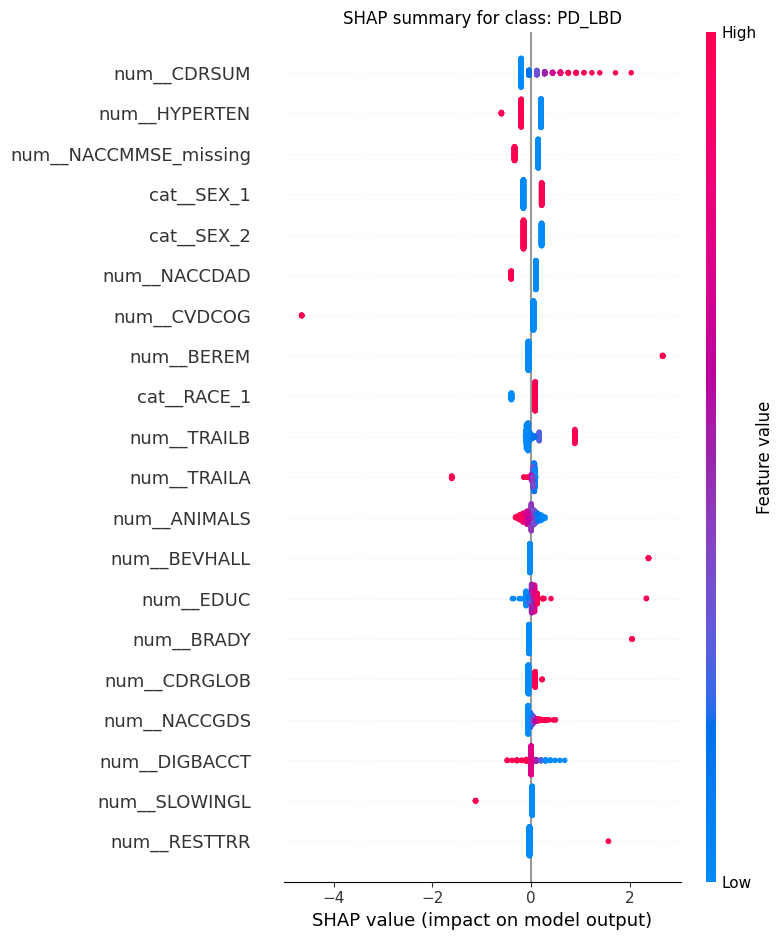

Saved: ..\output\shap_outputs\figures\summary_PD_LBD.png

===== Global SHAP summary: Vascular =====


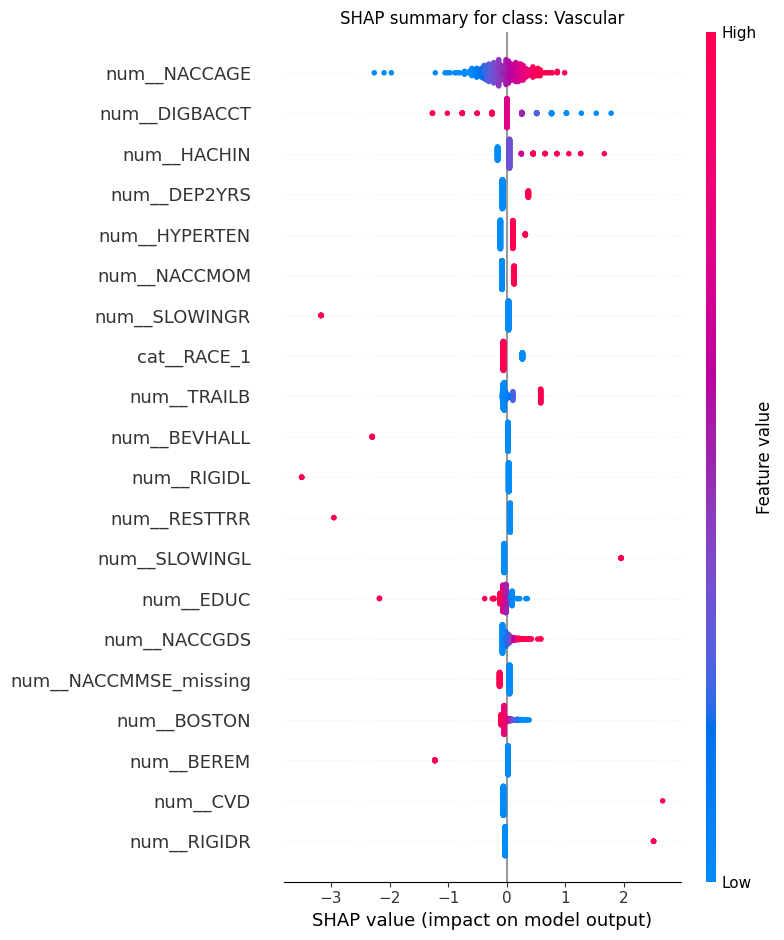

Saved: ..\output\shap_outputs\figures\summary_Vascular.png


In [8]:

for k, cls in enumerate(class_order):
    print(f"\n===== Global SHAP summary: {cls} =====")
    plt.figure()
    shap.summary_plot(
        shap_exp.values[:, :, k],
        X_explain,
        feature_names=feature_names_pre,
        show=False
    )
    plt.title(f"SHAP summary for class: {cls}")
    save_current_fig(f"summary_{cls}.png")


## 7) Global feature-importance tables

In [9]:

global_rows = []

for k, cls in enumerate(class_order):
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)
    tmp = pd.DataFrame({
        "feature": feature_names_pre,
        "mean_abs_shap": mean_abs_shap,
        "class": cls
    }).sort_values("mean_abs_shap", ascending=False)
    global_rows.append(tmp)

global_shap_df = pd.concat(global_rows, ignore_index=True)
global_csv = TABLE_DIR / "global_shap_importance_by_class.csv"
global_shap_df.to_csv(global_csv, index=False)

print("Saved:", global_csv)
display(global_shap_df.groupby("class", group_keys=False).head(15))


Saved: ..\output\shap_outputs\tables\global_shap_importance_by_class.csv


,feature,mean_abs_shap,class
0,num__CDRGLOB,0.237853,AD
1,num__CDRSUM,0.188561,AD
2,num__NACCMMSE_missing,0.183969,AD
3,num__NACCMOCA,0.167212,AD
4,num__NACCMMSE,0.157442,AD
5,cat__SEX_1,0.078494,AD
6,cat__SEX_2,0.076481,AD
7,num__NACCDAD,0.075495,AD
8,cat__RACE_1,0.062765,AD
9,num__DIGBACCT,0.054727,AD


In [10]:

collapsed_rows = []

for k, cls in enumerate(class_order):
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)
    tmp = pd.DataFrame({
        "feature_raw": feature_names_pre,
        "feature_base": [collapse_feature_name(f) for f in feature_names_pre],
        "mean_abs_shap": mean_abs_shap,
        "class": cls
    })
    tmp = (
        tmp.groupby(["class", "feature_base"], as_index=False)["mean_abs_shap"]
        .sum()
        .sort_values(["class", "mean_abs_shap"], ascending=[True, False])
    )
    collapsed_rows.append(tmp)

collapsed_global_shap_df = pd.concat(collapsed_rows, ignore_index=True)
collapsed_csv = TABLE_DIR / "global_shap_importance_collapsed.csv"
collapsed_global_shap_df.to_csv(collapsed_csv, index=False)

print("Saved:", collapsed_csv)
display(collapsed_global_shap_df.groupby("class", group_keys=False).head(15))


Saved: ..\output\shap_outputs\tables\global_shap_importance_collapsed.csv


,class,feature_base,mean_abs_shap
0,AD,CDRGLOB,0.237853
1,AD,CDRSUM,0.188561
2,AD,NACCMMSE_missing,0.183969
3,AD,NACCMOCA,0.167212
4,AD,NACCMMSE,0.157442
5,AD,SEX,0.154975
6,AD,RACE,0.124845
7,AD,NACCDAD,0.075495
8,AD,DIGBACCT,0.054727
9,AD,NACCAGE,0.052135


## 8) Bar plots of top collapsed features per class

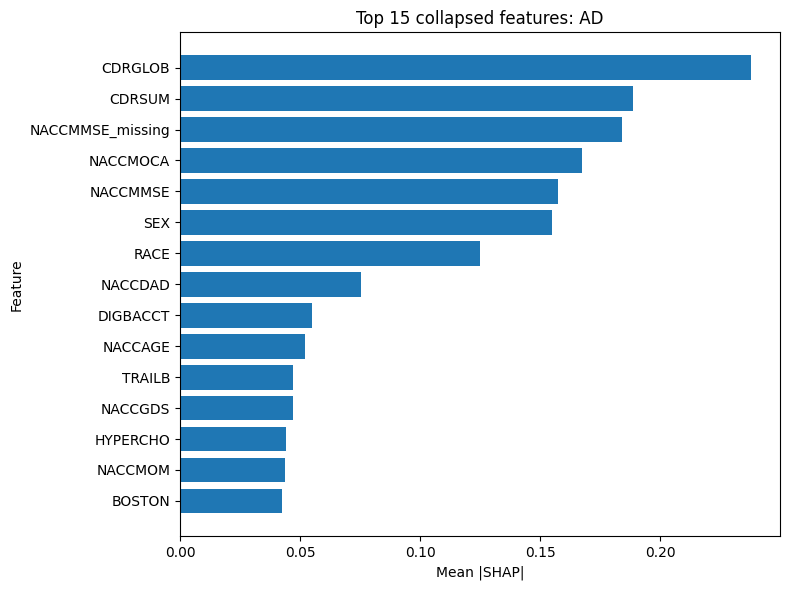

Saved: ..\output\shap_outputs\figures\bar_top_15_AD.png


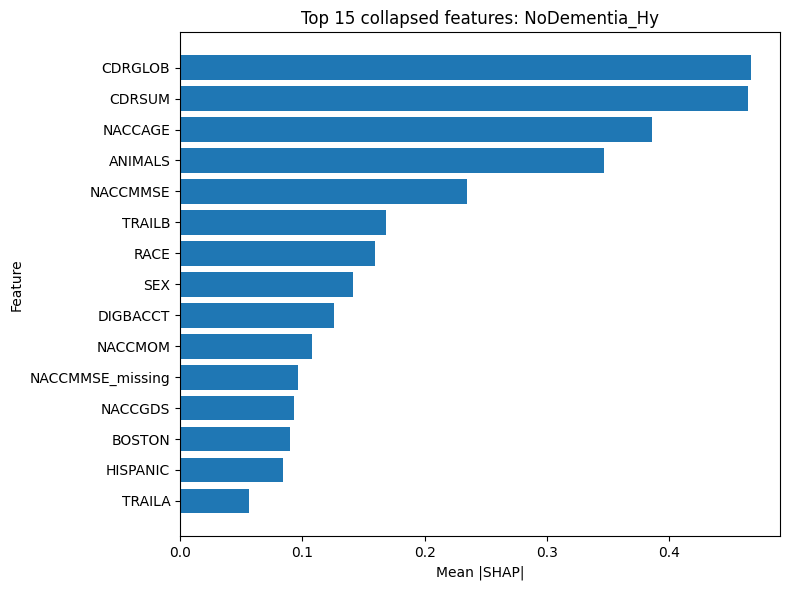

Saved: ..\output\shap_outputs\figures\bar_top_15_NoDementia_Hy.png


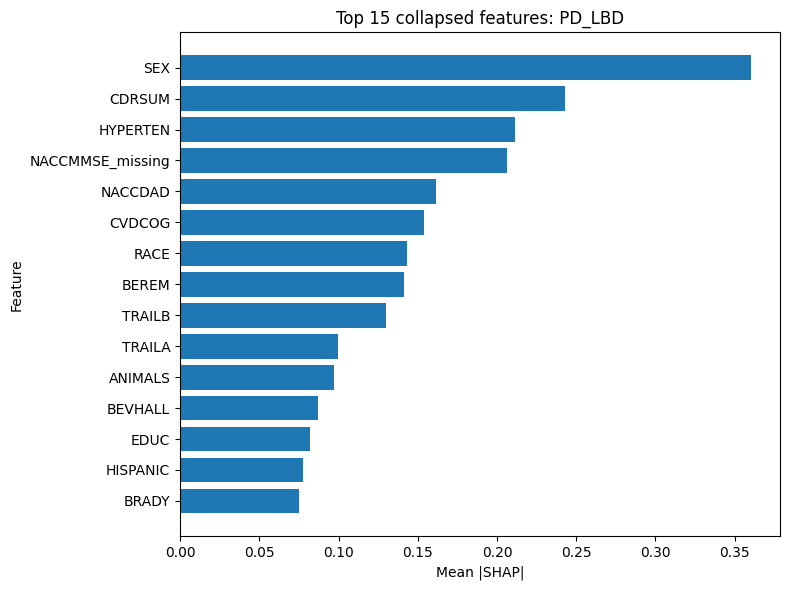

Saved: ..\output\shap_outputs\figures\bar_top_15_PD_LBD.png


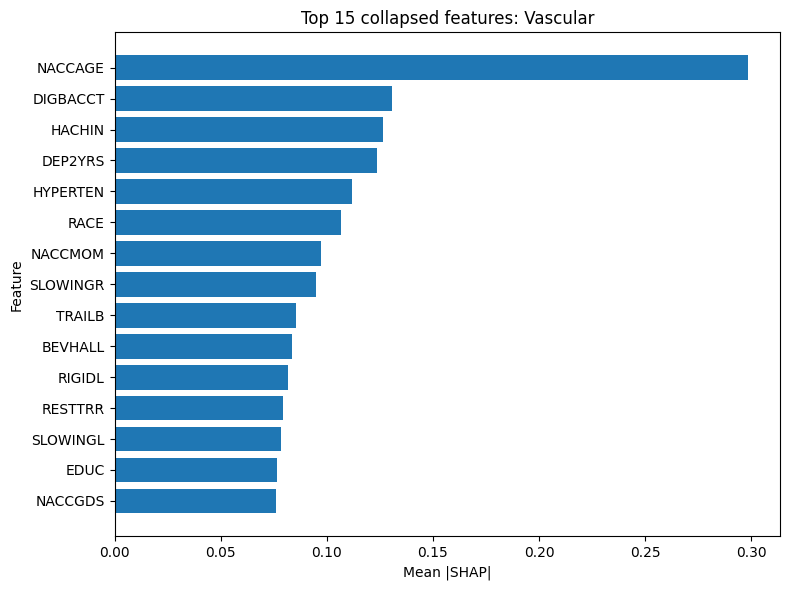

Saved: ..\output\shap_outputs\figures\bar_top_15_Vascular.png


In [11]:

TOP_N = 15

for cls in class_order:
    sub = (
        collapsed_global_shap_df[collapsed_global_shap_df["class"] == cls]
        .sort_values("mean_abs_shap", ascending=False)
        .head(TOP_N)
        .iloc[::-1]
    )

    plt.figure(figsize=(8, 6))
    plt.barh(sub["feature_base"], sub["mean_abs_shap"])
    plt.xlabel("Mean |SHAP|")
    plt.ylabel("Feature")
    plt.title(f"Top {TOP_N} collapsed features: {cls}")
    save_current_fig(f"bar_top_{TOP_N}_{cls}.png")


## 9) Threshold-aware prediction table for the vascular override

In [12]:

proba_test = clf_best.predict_proba(X_test)
base_pred_test = np.array([class_order[np.argmax(p)] for p in proba_test])
final_pred_test = predict_with_vascular_threshold(proba_test, class_order, best_T)

vas_idx = list(class_order).index("Vascular")

threshold_df = pd.DataFrame({
    "NACCID": df4.loc[X_test.index, "NACCID"].values,
    "true_label": y_test.values,
    "base_pred": base_pred_test,
    "final_pred": final_pred_test,
    "prob_vascular": proba_test[:, vas_idx],
    "vascular_threshold": best_T,
    "vascular_margin": proba_test[:, vas_idx] - best_T
})

threshold_csv = TABLE_DIR / "vascular_threshold_analysis_test.csv"
threshold_df.to_csv(threshold_csv, index=False)

print("Saved:", threshold_csv)
display(threshold_df.head(10))


Saved: ..\output\shap_outputs\tables\vascular_threshold_analysis_test.csv


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin
0,NACC056862,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.003717,0.36,-0.356283
1,NACC774813,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001510,0.36,-0.358490
2,NACC989206,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.002761,0.36,-0.357239
3,NACC735141,AD,AD,AD,0.028955,0.36,-0.331045
4,NACC252819,NoDementia_Hy,AD,AD,0.025498,0.36,-0.334502
5,NACC205986,NoDementia_Hy,AD,AD,0.017977,0.36,-0.342023
6,NACC148349,Vascular,AD,AD,0.051634,0.36,-0.308366
7,NACC029156,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.006010,0.36,-0.353990
8,NACC522352,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001104,0.36,-0.358896
9,NACC532829,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001065,0.36,-0.358935


## 10) Local explanations for selected participants

This cell shows local waterfall plots for a few examples.  
You can change `example_indices` to explain any test-set rows you want.


In [13]:

# Pick up to one row from each class if available
example_indices = []
for cls in class_order:
    idxs = np.where(y_test.values == cls)[0]
    if len(idxs) > 0:
        example_indices.append(int(idxs[0]))

print("Selected local explanation indices:", example_indices)


Selected local explanation indices: [3, 0, 45, 6]


Test row index: 3
NACCID       : NACC735141
True label   : AD
Final pred   : AD
Probabilities: {np.str_('AD'): np.float64(0.8102), np.str_('NoDementia_Hy'): np.float64(0.0824), np.str_('PD_LBD'): np.float64(0.0785), np.str_('Vascular'): np.float64(0.029)}
Vascular margin: -0.3310

--- Waterfall for class: AD ---


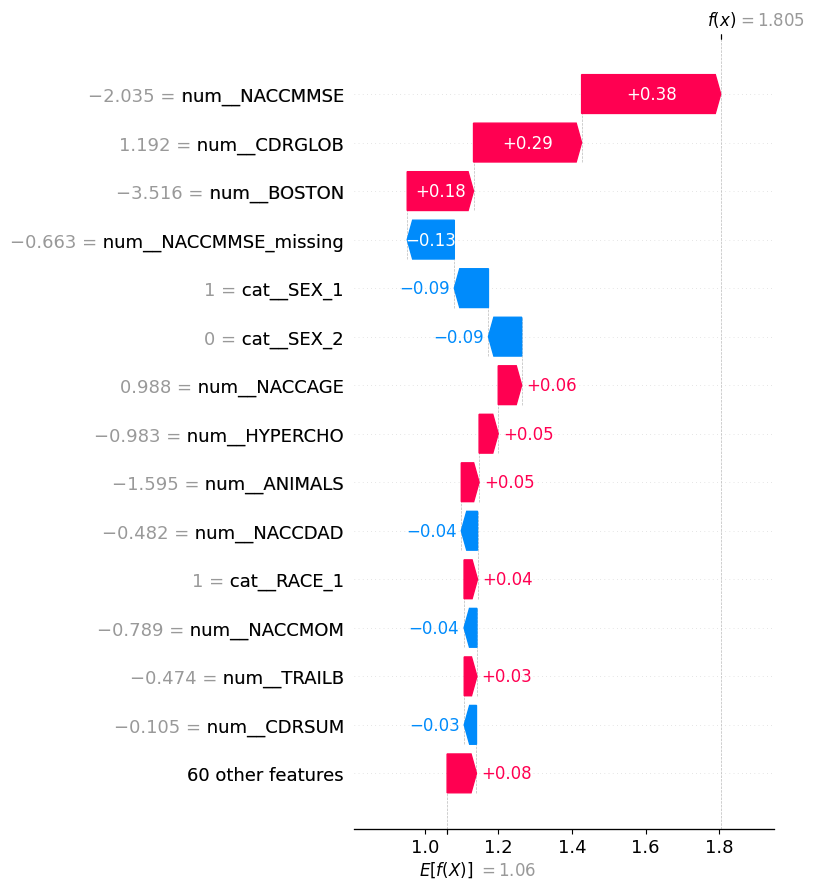

Saved: ..\output\shap_outputs\figures\waterfall_testidx_3_AD.png

--- Waterfall for class: NoDementia_Hy ---


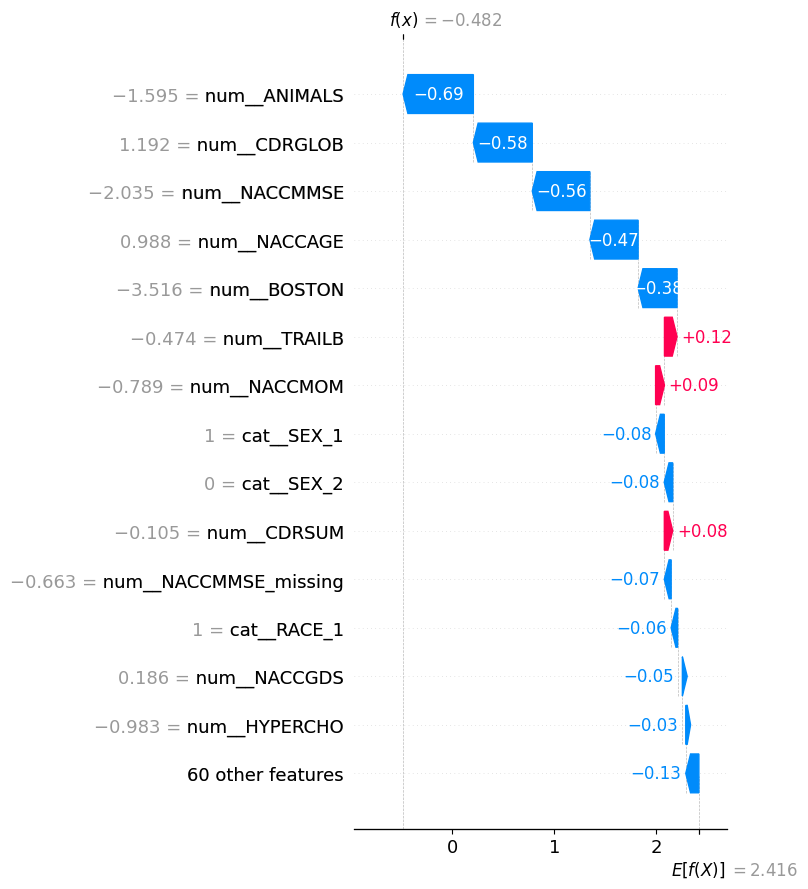

Saved: ..\output\shap_outputs\figures\waterfall_testidx_3_NoDementia_Hy.png

--- Waterfall for class: PD_LBD ---


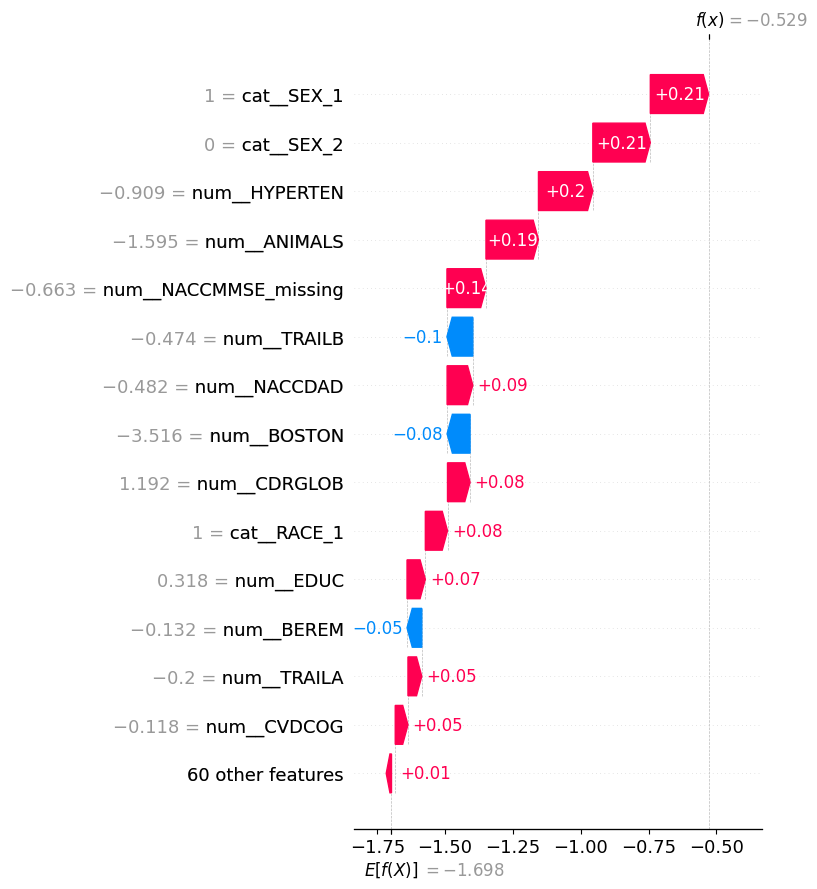

Saved: ..\output\shap_outputs\figures\waterfall_testidx_3_PD_LBD.png

--- Waterfall for class: Vascular ---


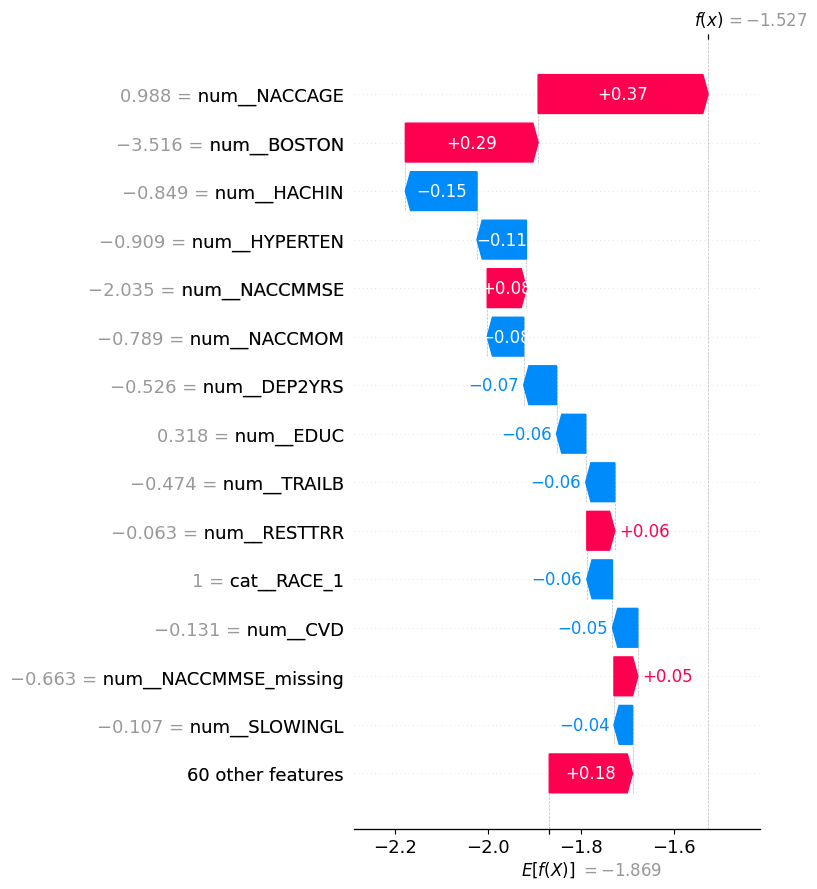

Saved: ..\output\shap_outputs\figures\waterfall_testidx_3_Vascular.png
Test row index: 0
NACCID       : NACC056862
True label   : NoDementia_Hy
Final pred   : NoDementia_Hy
Probabilities: {np.str_('AD'): np.float64(0.0847), np.str_('NoDementia_Hy'): np.float64(0.9091), np.str_('PD_LBD'): np.float64(0.0025), np.str_('Vascular'): np.float64(0.0037)}
Vascular margin: -0.3563

--- Waterfall for class: AD ---


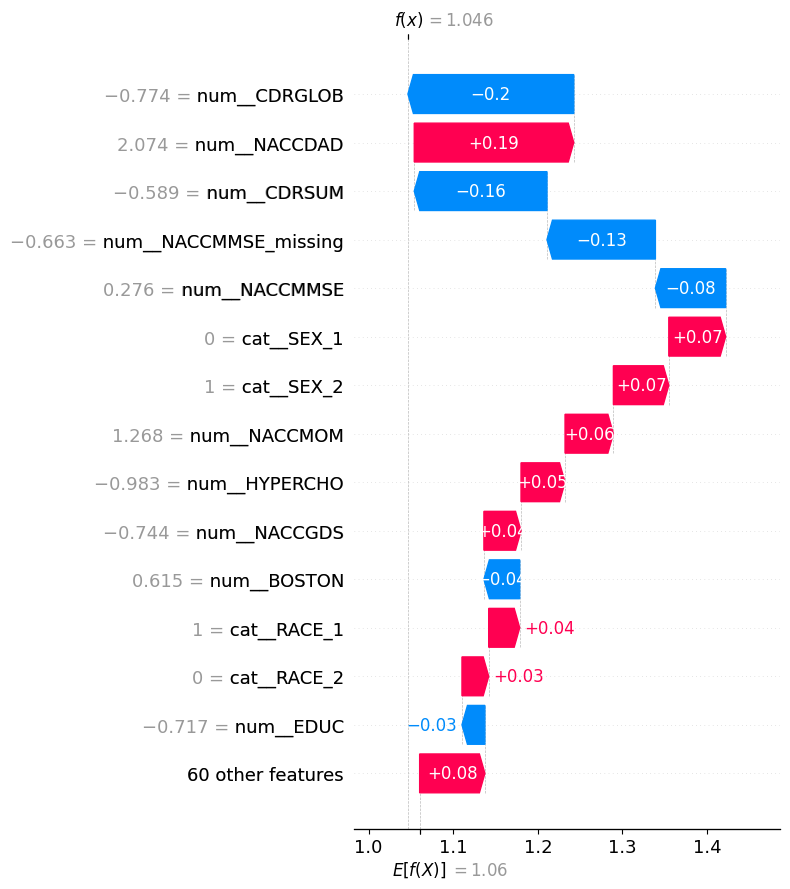

Saved: ..\output\shap_outputs\figures\waterfall_testidx_0_AD.png

--- Waterfall for class: NoDementia_Hy ---


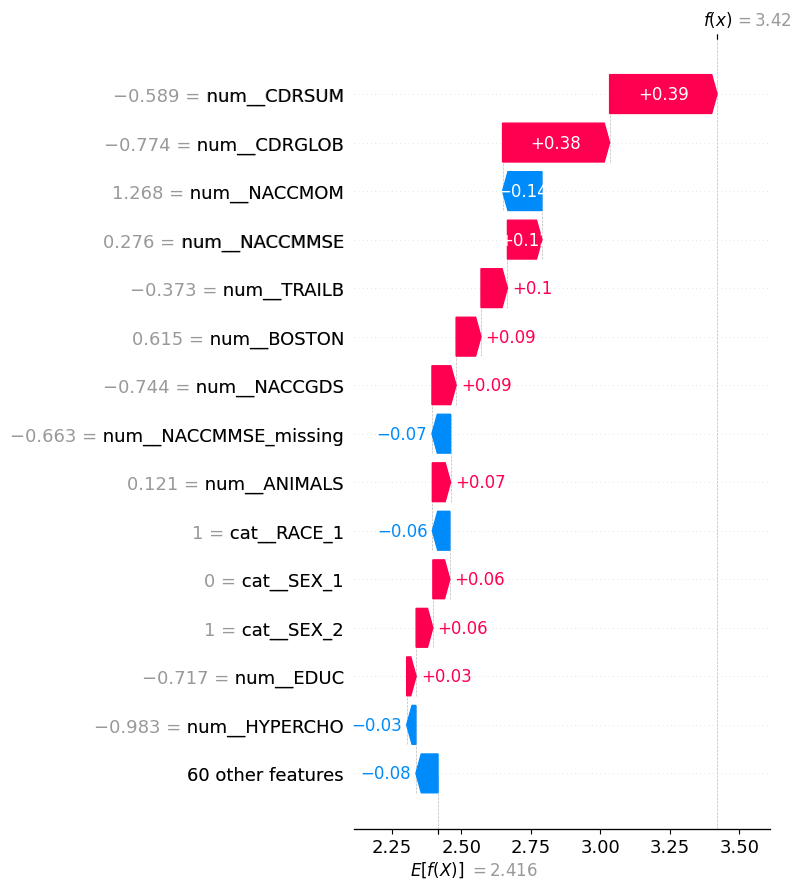

Saved: ..\output\shap_outputs\figures\waterfall_testidx_0_NoDementia_Hy.png

--- Waterfall for class: PD_LBD ---


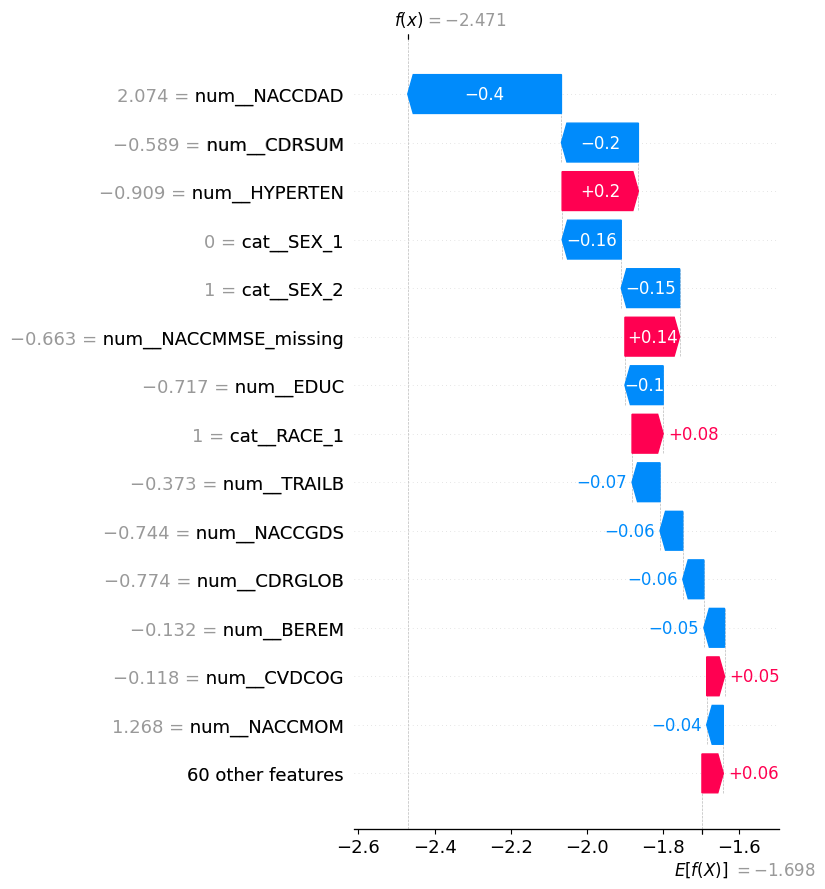

Saved: ..\output\shap_outputs\figures\waterfall_testidx_0_PD_LBD.png

--- Waterfall for class: Vascular ---


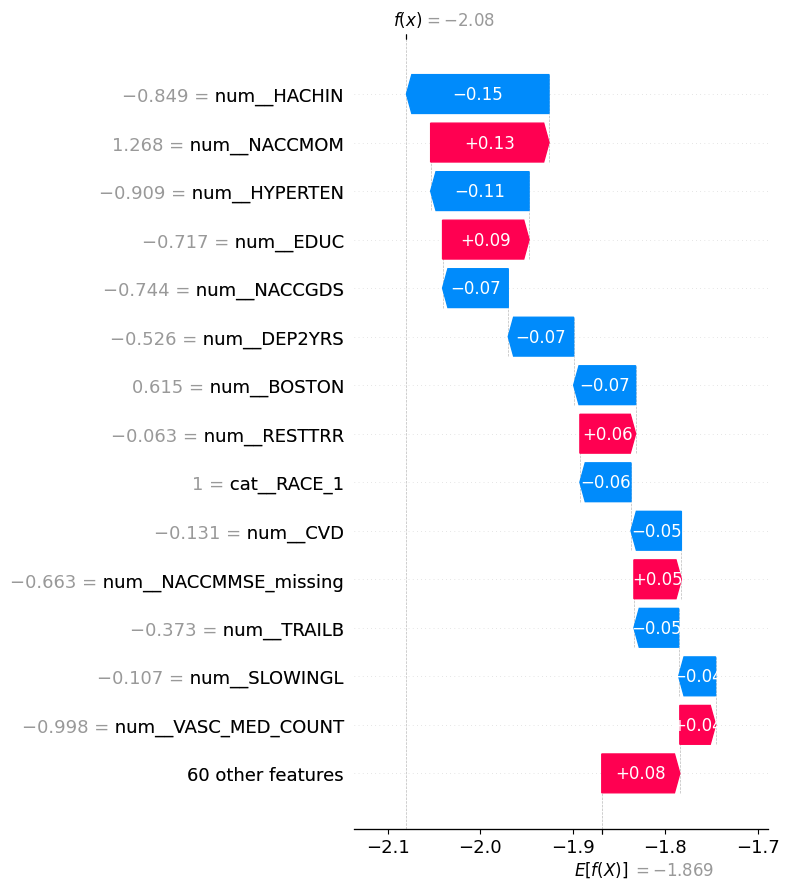

Saved: ..\output\shap_outputs\figures\waterfall_testidx_0_Vascular.png
Test row index: 45
NACCID       : NACC715142
True label   : PD_LBD
Final pred   : PD_LBD
Probabilities: {np.str_('AD'): np.float64(0.0051), np.str_('NoDementia_Hy'): np.float64(0.0014), np.str_('PD_LBD'): np.float64(0.9934), np.str_('Vascular'): np.float64(0.0)}
Vascular margin: -0.3600

--- Waterfall for class: AD ---


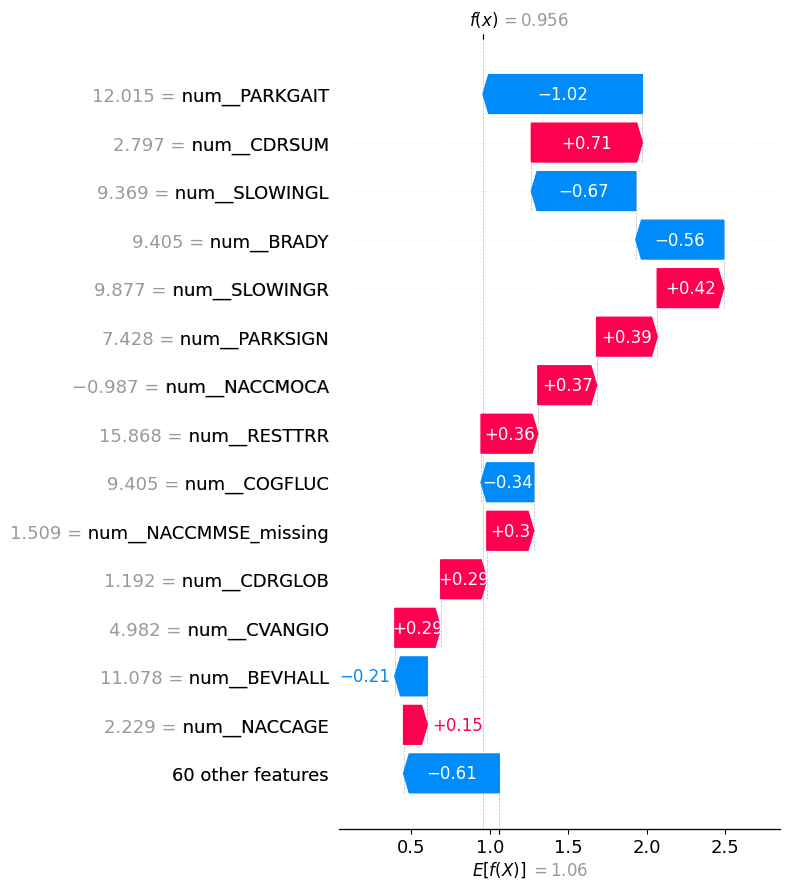

Saved: ..\output\shap_outputs\figures\waterfall_testidx_45_AD.png

--- Waterfall for class: NoDementia_Hy ---


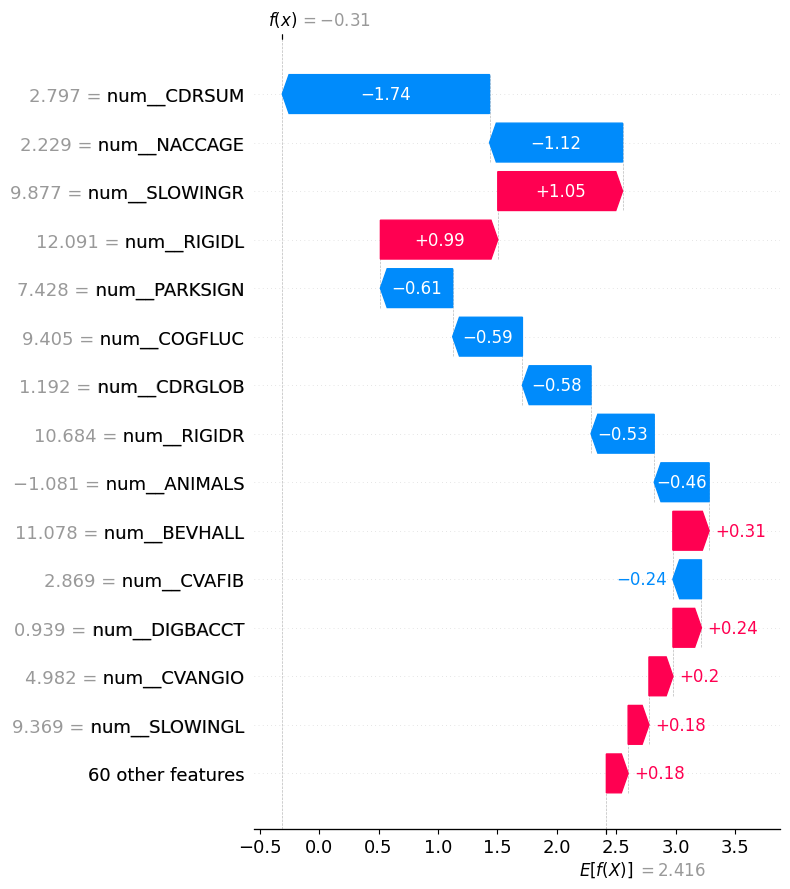

Saved: ..\output\shap_outputs\figures\waterfall_testidx_45_NoDementia_Hy.png

--- Waterfall for class: PD_LBD ---


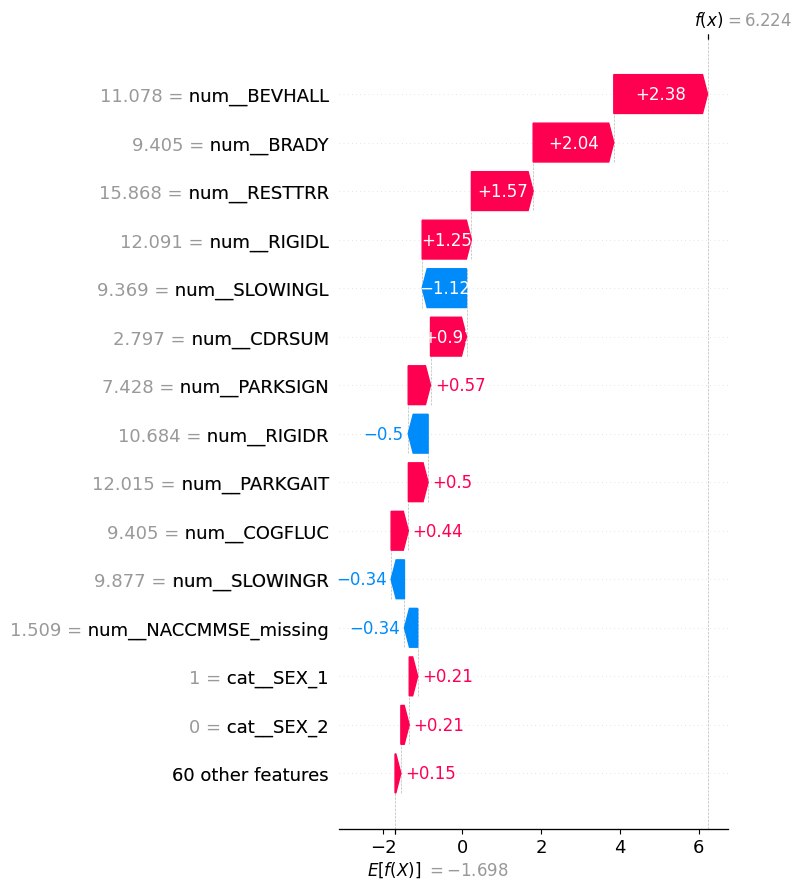

Saved: ..\output\shap_outputs\figures\waterfall_testidx_45_PD_LBD.png

--- Waterfall for class: Vascular ---


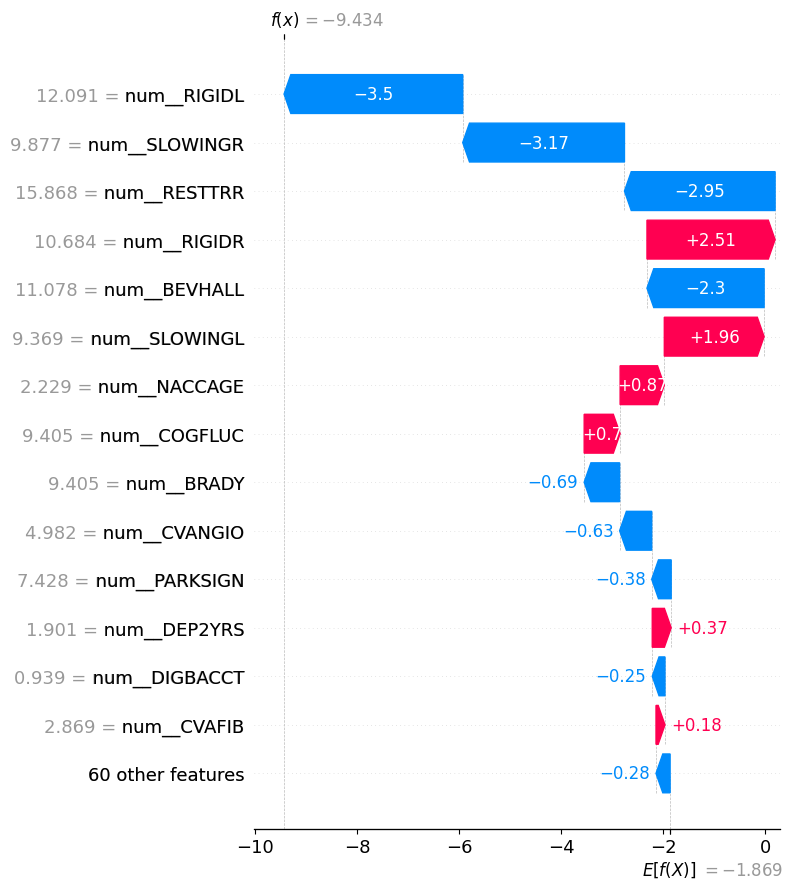

Saved: ..\output\shap_outputs\figures\waterfall_testidx_45_Vascular.png
Test row index: 6
NACCID       : NACC148349
True label   : Vascular
Final pred   : AD
Probabilities: {np.str_('AD'): np.float64(0.6637), np.str_('NoDementia_Hy'): np.float64(0.128), np.str_('PD_LBD'): np.float64(0.1566), np.str_('Vascular'): np.float64(0.0516)}
Vascular margin: -0.3084

--- Waterfall for class: AD ---


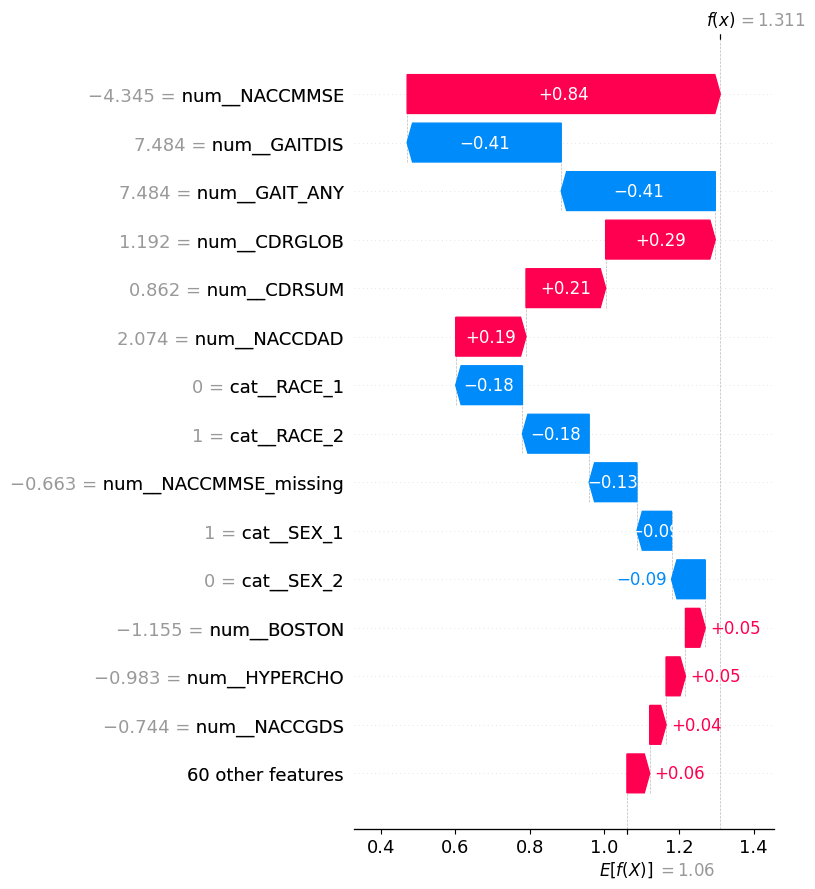

Saved: ..\output\shap_outputs\figures\waterfall_testidx_6_AD.png

--- Waterfall for class: NoDementia_Hy ---


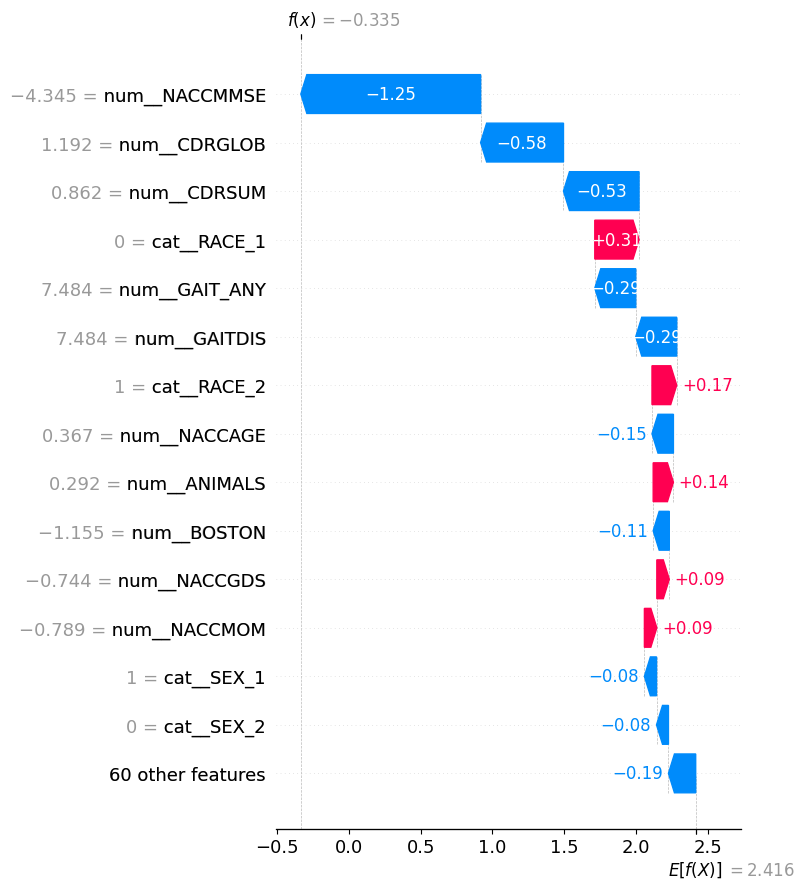

Saved: ..\output\shap_outputs\figures\waterfall_testidx_6_NoDementia_Hy.png

--- Waterfall for class: PD_LBD ---


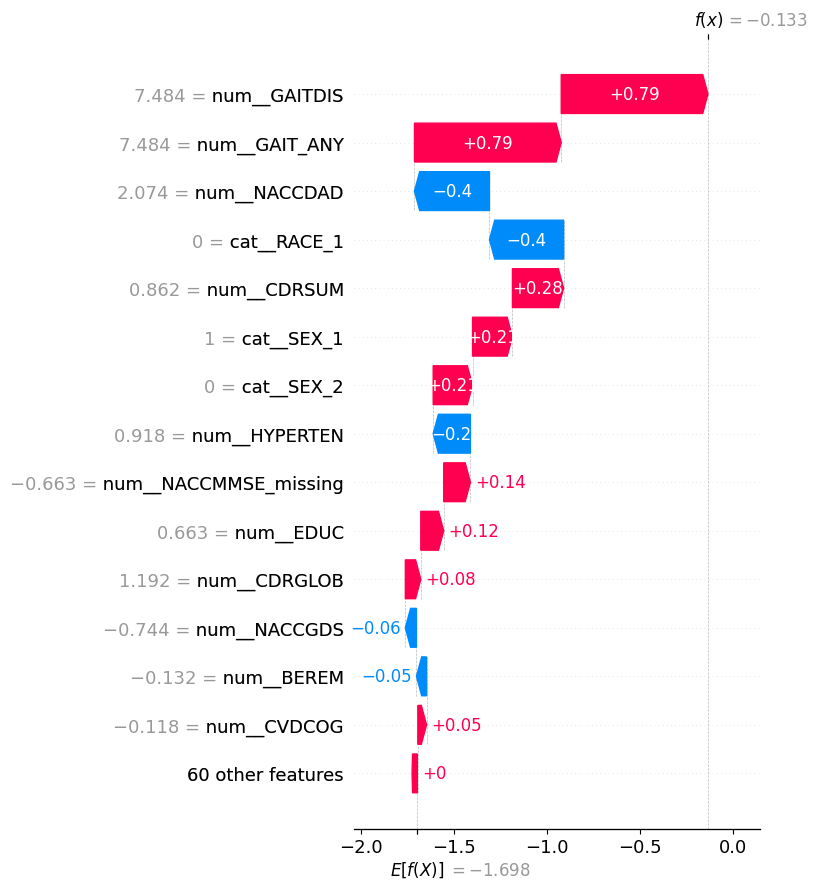

Saved: ..\output\shap_outputs\figures\waterfall_testidx_6_PD_LBD.png

--- Waterfall for class: Vascular ---


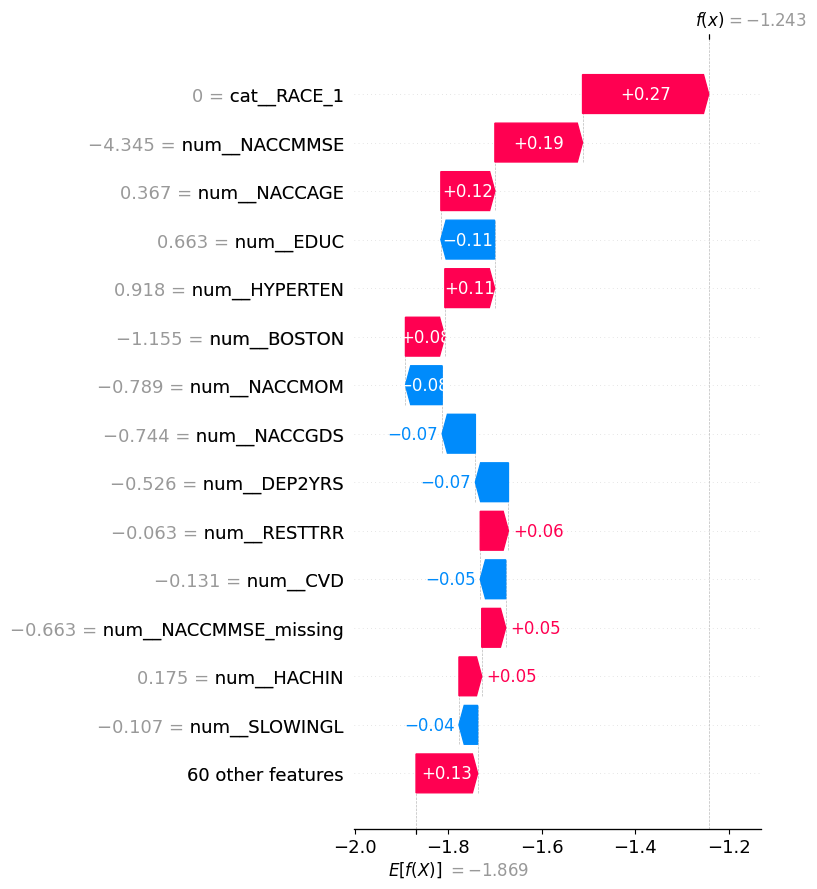

Saved: ..\output\shap_outputs\figures\waterfall_testidx_6_Vascular.png


In [14]:

for i in example_indices:
    naccid = df4.loc[X_test.index[i], "NACCID"]
    true_label = y_test.iloc[i]
    proba_i = clf_best.predict_proba(X_test.iloc[[i]])[0]
    final_pred_i = predict_with_vascular_threshold(proba_i.reshape(1, -1), class_order, best_T)[0]

    print("=" * 80)
    print(f"Test row index: {i}")
    print(f"NACCID       : {naccid}")
    print(f"True label   : {true_label}")
    print(f"Final pred   : {final_pred_i}")
    print(f"Probabilities: {dict(zip(class_order, np.round(proba_i, 4)))}")
    print(f"Vascular margin: {proba_i[vas_idx] - best_T:.4f}")

    x_row_dense = row_to_dense(X_explain[i])

    for k, cls in enumerate(class_order):
        print(f"\n--- Waterfall for class: {cls} ---")

        if np.ndim(shap_exp.base_values) == 2:
            base_val = shap_exp.base_values[i, k]
        else:
            base_val = shap_exp.base_values[k]

        single_exp = shap.Explanation(
            values=shap_exp.values[i, :, k],
            base_values=base_val,
            data=x_row_dense,
            feature_names=feature_names_pre
        )

        plt.figure()
        shap.plots.waterfall(single_exp, max_display=15, show=False)
        save_current_fig(f"waterfall_testidx_{i}_{cls}.png")


## 11) Export top local SHAP drivers per subject

In [15]:

rows = []

for i in range(sample_size):
    naccid = df4.loc[X_test.index[i], "NACCID"]
    for k, cls in enumerate(class_order):
        vals = shap_exp.values[i, :, k]
        top_idx = np.argsort(np.abs(vals))[::-1][:10]
        for rank, j in enumerate(top_idx, start=1):
            rows.append({
                "NACCID": naccid,
                "class": cls,
                "rank": rank,
                "feature_raw": feature_names_pre[j],
                "feature_base": collapse_feature_name(feature_names_pre[j]),
                "shap_value": vals[j]
            })

local_top_shap_df = pd.DataFrame(rows)
local_csv = TABLE_DIR / "local_top10_shap_per_subject.csv"
local_top_shap_df.to_csv(local_csv, index=False)

print("Saved:", local_csv)
display(local_top_shap_df.head(20))


Saved: ..\output\shap_outputs\tables\local_top10_shap_per_subject.csv


,NACCID,class,rank,feature_raw,feature_base,shap_value
0,NACC056862,AD,1,num__CDRGLOB,CDRGLOB,-0.196033
1,NACC056862,AD,2,num__NACCDAD,NACCDAD,0.188543
2,NACC056862,AD,3,num__CDRSUM,CDRSUM,-0.156900
3,NACC056862,AD,4,num__NACCMMSE_missing,NACCMMSE_missing,-0.128152
4,NACC056862,AD,5,num__NACCMMSE,NACCMMSE,-0.083075
5,NACC056862,AD,6,cat__SEX_1,SEX,0.067225
6,NACC056862,AD,7,cat__SEX_2,SEX,0.065502
7,NACC056862,AD,8,num__NACCMOM,NACCMOM,0.057159
8,NACC056862,AD,9,num__HYPERCHO,HYPERCHO,0.052031
9,NACC056862,AD,10,num__NACCGDS,NACCGDS,0.043876


## 12) Optional: find interesting vascular cases near the decision boundary

These are often the most useful cases for a paper or poster because they show why the threshold override mattered.


In [16]:

interesting_vascular = threshold_df.assign(
    abs_margin=lambda d: np.abs(d["vascular_margin"])
).sort_values(["final_pred", "abs_margin"], ascending=[True, True])

display(
    interesting_vascular[
        ["NACCID", "true_label", "base_pred", "final_pred", "prob_vascular", "vascular_threshold", "vascular_margin"]
    ].head(20)
)


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin
1576,NACC776644,AD,AD,AD,0.337753,0.36,-0.022247
1401,NACC132410,NoDementia_Hy,AD,AD,0.335628,0.36,-0.024372
1680,NACC509898,NoDementia_Hy,AD,AD,0.311909,0.36,-0.048091
1866,NACC580504,NoDementia_Hy,AD,AD,0.308425,0.36,-0.051575
2785,NACC343175,AD,AD,AD,0.299750,0.36,-0.060250
2570,NACC789678,AD,AD,AD,0.280197,0.36,-0.079803
786,NACC333018,AD,AD,AD,0.280064,0.36,-0.079936
1245,NACC748379,Vascular,AD,AD,0.277114,0.36,-0.082886
2373,NACC603157,NoDementia_Hy,AD,AD,0.260015,0.36,-0.099985
617,NACC644290,AD,AD,AD,0.255117,0.36,-0.104883


## 13) Notes for interpretation

- SHAP values here explain the **multiclass logistic regression after preprocessing**
- The final classifier also uses a **vascular threshold override**, so use:
  - SHAP for the **Vascular** class
  - plus `vascular_margin = prob_vascular - threshold`
- For presentation, the **collapsed feature tables** are usually much easier to read than raw one-hot encoded features
